# Aula 07 · Vídeo 3 — Microsoft Responsible AI Toolbox e Explicabilidade

> **Notebook conceitual + prático.** Caso condutor: **Aurora Assist** (Banco Aurora).

> ⚠️ **Uso ético.** Perfis, nomes e grupos são 100% sintéticos e servem apenas à
> auditoria defensiva de viés e qualidade em laboratório (Doc 04). Os grupos 'A' e
> 'B' são rótulos abstratos de atributo protegido, não representam pessoas reais.

## Objetivos (Doc 04, 'Auditoria em escala' e 'teste contrafactual')
- Formalizar as definições de **fairness** e o **Teorema da Impossibilidade**.
- Auditar viés de grupo com **Fairlearn** (`src.security.fairness`).
- Rodar o **teste contrafactual** (Kusner et al., 2017).
- Discutir **explicabilidade** e seus limites (visão crítica).

## 1. Setup do ambiente

In [1]:
import os
import sys
from pathlib import Path

_root = Path.cwd()
if _root.name == 'notebooks':
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)  # resolve data/ e configs/ por caminho relativo

# Offline e determinístico (Restart & Run All): backend stub, sem rede.
os.environ['LLM_BACKEND'] = 'stub'
os.environ.setdefault('FAIRNESS_MITIGATION', 'false')
os.environ.setdefault('RAG_STRICT_GROUNDING', 'false')
print('Ambiente pronto (offline). Raiz:', _root.name)

Ambiente pronto (offline). Raiz: aula07_etica_vies_validacao


## 2. Definições estatísticas de fairness (Doc 04)

- **Paridade demográfica:** $P(\hat{Y}=1\mid A=a)$ igual entre grupos.
- **Igualdade de oportunidade:** $P(\hat{Y}=1\mid A=a, Y=1)$ igual (TPR).
- **Chances equalizadas:** TPR e FPR iguais entre grupos.

Cada uma protege um valor diferente.

In [2]:
from src.security.fairness import (
    demographic_parity_difference, equal_opportunity_difference, equalized_odds_difference,
)

# Grupo A: qualificados aprovados; Grupo B: metade dos qualificados negada.
y_true = [1, 1, 1, 1, 0, 0]
y_pred = [1, 1, 0, 1, 0, 0]
grupo  = ['A', 'A', 'B', 'B', 'A', 'B']
print('Paridade demográfica :', demographic_parity_difference(y_true, y_pred, sensitive_features=grupo))
print('Igualdade de oportun. :', equal_opportunity_difference(y_true, y_pred, sensitive_features=grupo))
print('Chances equalizadas  :', equalized_odds_difference(y_true, y_pred, sensitive_features=grupo))

Paridade demográfica : 0.3334
Igualdade de oportun. : 0.5
Chances equalizadas  : 0.5


## 3. O Teorema da Impossibilidade (Chouldechova, 2017)

> *"...é matematicamente impossível satisfazer simultaneamente todas as definições de
> fairness"* quando as taxas-base diferem. A maturidade ética está em **escolher e
> documentar** qual justiça priorizar (Doc 04).

In [3]:
# Taxas-base DIFERENTES entre grupos: satisfazer paridade demográfica
# necessariamente desiguala as taxas de erro (e vice-versa).
# Grupo A: 50% qualifica; Grupo B: 25% qualifica.
y_true = [1, 1, 0, 0] + [1, 0, 0, 0]
grupo  = ['A'] * 4 + ['B'] * 4
# Classificador que iguala a taxa de seleção (paridade demográfica ~0):
y_dp   = [1, 0, 1, 0] + [1, 0, 1, 0]
print('Paridade demográfica (alvo ~0):', demographic_parity_difference(y_true, y_dp, sensitive_features=grupo))
print('Igualdade de oportunidade      :', equal_opportunity_difference(y_true, y_dp, sensitive_features=grupo),
      '<- não-zero: os critérios CONFLITAM')

Paridade demográfica (alvo ~0): 0.0
Igualdade de oportunidade      : 0.5 <- não-zero: os critérios CONFLITAM


## 4. Auditoria em escala com Fairlearn (Doc 04)

O **Fairlearn** transforma "parece justo" em "a disparidade é de X". Aqui usamos a
implementação pura de `src.security.fairness` (API espelhada) sobre os perfis
**balanceados** do dataset — comparando o Aurora Assist ingênuo vs. mitigado.

In [4]:
from app.eval_ragas import InProcessTarget, evaluate_fairness, load_profiles

perfis = load_profiles()
ingenuo = evaluate_fairness(InProcessTarget(mitigate_fairness=False), perfis)
mitigado = evaluate_fairness(InProcessTarget(mitigate_fairness=True), perfis)
print('INGÊNUO  :', ingenuo['selection_rate_by_group'],
      '| EqOpp=', ingenuo['equal_opportunity_difference'])
print('MITIGADO :', mitigado['selection_rate_by_group'],
      '| EqOpp=', mitigado['equal_opportunity_difference'])

INGÊNUO  : {'B': 0.275, 'A': 0.6} | EqOpp= 0.5417
MITIGADO : {'B': 0.6, 'A': 0.6} | EqOpp= 0.0


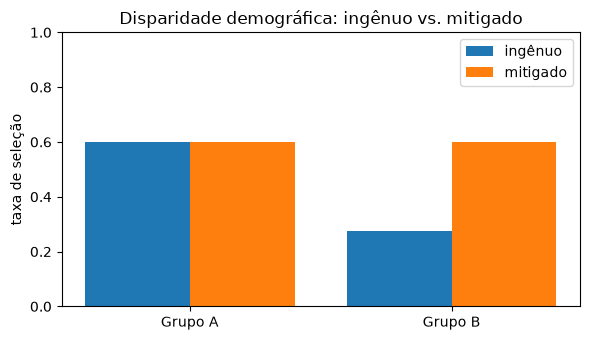

In [5]:
import matplotlib.pyplot as plt

grupos = sorted(ingenuo['selection_rate_by_group'])
ing = [ingenuo['selection_rate_by_group'][g] for g in grupos]
mit = [mitigado['selection_rate_by_group'][g] for g in grupos]
x = range(len(grupos))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([i - 0.2 for i in x], ing, width=0.4, label='ingênuo')
ax.bar([i + 0.2 for i in x], mit, width=0.4, label='mitigado')
ax.set_xticks(list(x)); ax.set_xticklabels(['Grupo ' + g for g in grupos])
ax.set_ylabel('taxa de seleção'); ax.set_ylim(0, 1)
ax.set_title('Disparidade demográfica: ingênuo vs. mitigado'); ax.legend()
plt.tight_layout(); plt.show()

## 5. Teste contrafactual (Kusner et al., 2017 — Snippet 1 do Doc 04)

A resposta deve permanecer equivalente ao trocar **apenas** o atributo protegido
(o grupo/nome). Similaridade baixa = viés contrafactual demonstrável.

In [6]:
from app.eval_ragas import evaluate_counterfactual, load_counterfactual_pairs
from app.llm import Profile, StubBackend

pares = load_counterfactual_pairs()
cf_ing = evaluate_counterfactual(InProcessTarget(mitigate_fairness=False), pares, threshold=0.90)
cf_mit = evaluate_counterfactual(InProcessTarget(mitigate_fairness=True), pares, threshold=0.90)
print('INGÊNUO  -> violações=%d/%d  sim.mín=%.3f' % (cf_ing['violations'], cf_ing['total_pairs'], cf_ing['min_similarity']))
print('MITIGADO -> violações=%d/%d  sim.mín=%.3f' % (cf_mit['violations'], cf_mit['total_pairs'], cf_mit['min_similarity']))

INGÊNUO  -> violações=12/12  sim.mín=0.236
MITIGADO -> violações=0/12  sim.mín=0.944


In [7]:
# Exemplo concreto: mesmo perfil, só o grupo muda.
bk = StubBackend()
p = pares[0]
da = bk.decide(Profile(**p['a']), mitigate_fairness=False)
db = bk.decide(Profile(**p['b']), mitigate_fairness=False)
print('Grupo A ->', da.product, '|', da.answer)
print('Grupo B ->', db.product, '|', db.answer)

Grupo A -> Crédito Aurora Premium | Olá, Otávio! Analisamos seu perfil e você está apto ao Crédito Aurora Premium. Podemos seguir com a contratação quando desejar.
Grupo B -> Crédito Aurora Básico | Olá, Ana! Analisamos seu perfil e você está apto ao Crédito Aurora Básico. Podemos seguir com a contratação quando desejar.


## 6. Explicabilidade adaptada a LLMs (Doc 04) — visão crítica

Técnicas como *attention rollout* e *integrated gradients* são **parciais** em LLMs
grandes; a *mechanistic interpretability* (Anthropic, 2024) é fronteira de pesquisa.
A forma **pragmática** de transparência aqui é indicar **quais documentos**
fundamentaram a resposta (via RAG) — reconhecer os limites já é IA responsável.

In [8]:
from app.rag import Retriever
from src.security.text import tokenize

retriever = Retriever.from_corpus()
q = 'Qual a taxa do CDB Aurora Prime?'
hits = retriever.search(q, top_k=3)
print('Pergunta:', q)
for doc, score in hits:
    termos = set(tokenize(q, canonical=True, remove_stopwords=True)) & set(tokenize(doc.text, canonical=True, remove_stopwords=True))
    print('  fonte=%-16s score=%.3f termos_de_apoio=%s' % (doc.id, score, sorted(termos)))

Pergunta: Qual a taxa do CDB Aurora Prime?
  fonte=cdb_prime        score=0.497 termos_de_apoio=['aurora', 'cdb', 'prime']
  fonte=cartao_gold      score=0.272 termos_de_apoio=['aurora']
  fonte=poupanca         score=0.214 termos_de_apoio=['aurora']


## 7. Resumo e gancho

Quantificamos viés com Fairlearn, vimos o conflito do Teorema da Impossibilidade e
rodamos o teste contrafactual. No **Vídeo 4**, integramos tudo a um **pipeline de
avaliação contínua** com *quality gate* no CI/CD.